# Variables climáticas adicionales para analizar el Índice de Aridez (IA) en Sinaloa

Este cuadernillo complementa los tres cuadernillos existentes. Conserva la convención de archivos `ppt_<año>_<mes>.tif`, `etp_<año>_<mes>.tif` y los productos anuales de `indice_aridez_anual/malla_4km`.

## Qué hace

1. Descarga en **un GeoTIFF multibanda por mes** variables adicionales de TerraClimate sobre Sinaloa y las alinea exactamente a la malla de tus archivos PPT/ETP.
2. Descarga índices climáticos mensuales de NOAA/PSL: PDO, SOI, Niño 3.4 y PNA. Además, intenta leer la tabla estacional de RONI del NOAA/CPC.
3. Calcula resúmenes anuales y de temporada, relaciona esas variables con PPT, ETP e IA y exporta tablas, figuras y un panel opcional píxel-año para tus modelos.

### Variables de TerraClimate propuestas

| Banda | Interpretación | Agregación anual |
|---|---|---|
| `tmmn`, `tmmx` | temperatura mínima y máxima | media de los 12 meses |
| `aet` | evapotranspiración real | suma de los 12 meses |
| `soil` | humedad del suelo | media |
| `vpd`, `vap` | déficit de presión de vapor y presión de vapor | media |
| `srad` | radiación de onda corta | media |
| `vs` | velocidad del viento a 10 m | media |
| `ro` | escurrimiento | suma |
| `def`, `pdsi` | déficit hídrico climático e índice de sequía de Palmer | `def`: suma; `pdsi`: media |

**Precaución metodológica:** `def` y `pdsi` son indicadores derivados de balance hídrico/sequía y pueden actuar como sustitutos muy cercanos del objetivo. Se conservan para analizarlos, pero recomiendo comparar un conjunto **meteorológico** (temperatura, humedad, viento, radiación, etc.) contra otro que incluya también **indicadores de sequía**. Si el objetivo es pronosticar años futuros, no uses índices o variables del mismo año que todavía no estarían disponibles al emitir el pronóstico; usa las columnas con rezago (`rezago1`) y una separación temporal de entrenamiento/prueba.

El IA de tus mapas es `PPT_anual / ETP_anual` **por píxel**. La media espacial del IA no debe reemplazarse por `media(PPT)/media(ETP)`. Las correlaciones anuales de este notebook son exploratorias; no garantizan que las métricas de los modelos mejoren.

## Fuentes

- TerraClimate en Google Earth Engine: https://developers.google.com/earth-engine/datasets/catalog/IDAHO_EPSCOR_TERRACLIMATE
- RONI, NOAA/CPC: https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso/roni/
- Índices PDO, SOI, Niño 3.4 y PNA, NOAA Physical Sciences Laboratory (PSL): https://psl.noaa.gov/data/climateindices/list/

## 1. Instalación (solo si hace falta)

Si alguna biblioteca no está instalada, ejecuta la siguiente celda quitando el comentario. Earth Engine requiere una cuenta/proyecto configurado y autenticación en el equipo donde se ejecute el cuadernillo.

In [8]:
# %pip install earthengine-api geemap rasterio pandas numpy matplotlib scipy requests beautifulsoup4

## 2. Configuración de rutas y variables

Ejecuta el notebook desde la carpeta del proyecto donde existen `mapas_sinaloa_mensual/` e `indice_aridez_anual/`. La descarga está configurada para reutilizar los archivos existentes y solo bajar los faltantes.

In [1]:
from pathlib import Path
import tifffile

carpeta = Path("variables_adicionales_terraclimate")
archivos = sorted(carpeta.glob("tc_extra_*.tif"))

print("Directorio actual:", Path.cwd())
print("Archivos encontrados:", len(archivos))

if archivos:
    ruta = archivos[0]

    with tifffile.TiffFile(ruta) as tif:
        serie = tif.series[0]
        datos = serie.asarray()

        print("Archivo de prueba:", ruta.name)
        print("Forma del arreglo:", datos.shape)
        print("Ejes TIFF:", serie.axes)
        print("Tipo de datos:", datos.dtype)
        print("Número de páginas:", len(tif.pages))

        print("\nEtiquetas de georreferenciación:")
        for codigo in [33550, 33922, 34264, 34735, 34736, 34737, 42113]:
            etiqueta = tif.pages[0].tags.get(codigo)
            if etiqueta is not None:
                print(etiqueta.name, "=", repr(etiqueta.value)[:300])
else:
    print("No se encontraron archivos en la carpeta esperada.")

Directorio actual: C:\Users\Leon1\Documents\Maestria\Semestre III\Movilidad\Tesis
Archivos encontrados: 804
Archivo de prueba: tc_extra_1958_01.tif
Forma del arreglo: (11, 130, 116)
Ejes TIFF: SYX
Tipo de datos: float32
Número de páginas: 1

Etiquetas de georreferenciación:
ModelPixelScaleTag = (0.03593261136478086, 0.03593261136478086, 0.0)
ModelTiepointTag = (0.0, 0.0, 0.0, -109.50021650229995, 27.081997500268713, 0.0)
GeoKeyDirectoryTag = (1, 1, 0, 10, 1024, 0, 1, 2, 1025, 0, 1, 1, 2048, 0, 1, 32767, 2049, 34737, 77, 0, 2050, 0, 1, 32767, 2054, 0, 1, 9102, 2056, 0, 1, 32767, 2057, 34736, 1, 0, 2059, 34736, 1, 1, 2061, 34736, 1, 2)
GeoDoubleParamsTag = (6378137.0, 298.257223563, 0.0)
GeoAsciiParamsTag = 'GCS Name = Greenwich|Datum = unnamed|Ellipsoid = unnamed|Primem = Greenwich||'
GDAL_NODATA = '-9999'


In [9]:
from pathlib import Path
import os
import re
import time
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling
from scipy import stats
from bs4 import BeautifulSoup

warnings.filterwarnings("ignore", category=RuntimeWarning)

# Carpetas de los cuadernillos existentes
RUTA_MENSUAL = Path("mapas_sinaloa_mensual")
RUTA_ANUAL = Path("indice_aridez_anual")
DIR_4KM = RUTA_ANUAL / "malla_4km"

# Carpetas nuevas
RUTA_EXTRA = Path("variables_adicionales_terraclimate")
RUTA_INDICES = Path("indices_climaticos_noaa")
RUTA_ANALISIS = RUTA_ANUAL / "analisis_variables_extra"
RUTA_TABLAS = RUTA_ANALISIS / "tablas"
RUTA_FIGURAS = RUTA_ANALISIS / "figuras"
for carpeta in [RUTA_EXTRA, RUTA_INDICES, RUTA_TABLAS, RUTA_FIGURAS]:
    carpeta.mkdir(parents=True, exist_ok=True)

NODATA = -9999.0
EE_PROJECT = "descarga-de-datoa"  # Si Earth Engine lo requiere, escribe aquí el ID del proyecto de Google Cloud.
DESCARGAR_VARIABLES_TERRACLIMATE = True
FORZAR_DESCARGA = False
ESCALA_EE_METROS = 4000
REINTENTOS = 3
ESPERA_SEG = 4
EXPORTAR_PANEL_PIXELES = True  # El panel comprimido puede tener cientos de miles de filas.

# Coordenadas de Sinaloa: [lon_min, lat_min, lon_max, lat_max]
BBOX_SINALOA_COORDS = [-109.4832, 22.4354, -105.3639, 27.0645]

# Banda GEE, factor de escala del catálogo y agregación para el raster anual.
# Las bandas de TerraClimate almacenan algunas variables con factor de escala.
VARIABLES_EXTRA = {
    "aet":  {"banda": "aet",  "escala": 0.1,   "agregacion": "suma",  "unidad": "mm/año"},
    "def":  {"banda": "def",  "escala": 0.1,   "agregacion": "suma",  "unidad": "mm/año"},
    "pdsi": {"banda": "pdsi", "escala": 0.01,  "agregacion": "media", "unidad": "índice"},
    "soil": {"banda": "soil", "escala": 0.1,   "agregacion": "media", "unidad": "mm (media mensual)"},
    "srad": {"banda": "srad", "escala": 0.1,   "agregacion": "media", "unidad": "W/m²"},
    "tmmn": {"banda": "tmmn", "escala": 0.1,   "agregacion": "media", "unidad": "°C"},
    "tmmx": {"banda": "tmmx", "escala": 0.1,   "agregacion": "media", "unidad": "°C"},
    "vap":  {"banda": "vap",  "escala": 0.001, "agregacion": "media", "unidad": "kPa"},
    "vpd":  {"banda": "vpd",  "escala": 0.01,  "agregacion": "media", "unidad": "kPa"},
    "vs":   {"banda": "vs",   "escala": 0.01,  "agregacion": "media", "unidad": "m/s"},
    "ro":   {"banda": "ro",   "escala": 1.0,   "agregacion": "suma",  "unidad": "mm/año"},
}

print("Mapas mensuales:", RUTA_MENSUAL.resolve())
print("Rasters anuales:", DIR_4KM.resolve())
print("Salida variables extra:", RUTA_EXTRA.resolve())

Mapas mensuales: C:\Users\Leon1\Documents\Maestria\Semestre III\Movilidad\Tesis\mapas_sinaloa_mensual
Rasters anuales: C:\Users\Leon1\Documents\Maestria\Semestre III\Movilidad\Tesis\indice_aridez_anual\malla_4km
Salida variables extra: C:\Users\Leon1\Documents\Maestria\Semestre III\Movilidad\Tesis\variables_adicionales_terraclimate


## 3. Detectar años completos y leer la malla de referencia

Por defecto, solo se consideran años para los que existan los 12 meses tanto de PPT como de ETP. Los rasters adicionales se remuestrean a la transformación, CRS, ancho y alto exactos del primer raster PPT disponible, para que puedan apilarse píxel a píxel con el IA.

In [10]:
PATRON_MENSUAL = re.compile(r"^(ppt|etp)_(\d{4})_(0[1-9]|1[0-2])\.tif$", re.I)
archivos_mensuales = {}
for ruta in RUTA_MENSUAL.glob("*.tif"):
    m = PATRON_MENSUAL.match(ruta.name)
    if m:
        archivos_mensuales[(m.group(1).lower(), int(m.group(2)), int(m.group(3)))] = ruta

anios_completos = []
for anio in sorted({k[1] for k in archivos_mensuales}):
    if all((var, anio, mes) in archivos_mensuales for var in ("ppt", "etp") for mes in range(1, 13)):
        anios_completos.append(anio)

if not anios_completos:
    raise FileNotFoundError(
        f"No se detectaron años completos en {RUTA_MENSUAL}. "
        "Ejecuta primero Descarga_mensual.ipynb y verifica la ruta."
    )

# Acotar por años opcionales si se desea probar una descarga pequeña.
ANIO_INICIO = None  # Ejemplo: 2000
ANIO_FIN = None     # Ejemplo: 2005
if ANIO_INICIO is not None:
    anios_completos = [a for a in anios_completos if a >= ANIO_INICIO]
if ANIO_FIN is not None:
    anios_completos = [a for a in anios_completos if a <= ANIO_FIN]

if not anios_completos:
    raise ValueError("El rango ANIO_INICIO/ANIO_FIN no coincide con los años completos detectados.")

# Primer PPT real como malla de referencia
ruta_ref = next(archivos_mensuales[("ppt", a, m)]
                for a in sorted({k[1] for k in archivos_mensuales})
                for m in range(1, 13) if ("ppt", a, m) in archivos_mensuales)
with rasterio.open(ruta_ref) as src:
    META_REF = src.profile.copy()
    CRS_REF = src.crs
    TRANSFORM_REF = src.transform
    WIDTH_REF, HEIGHT_REF = src.width, src.height

print(f"Años a procesar: {anios_completos[0]}–{anios_completos[-1]} ({len(anios_completos)} años)")
print(f"Malla de referencia: {WIDTH_REF} x {HEIGHT_REF} | CRS={CRS_REF} | archivo={ruta_ref}")

Años a procesar: 1958–2024 (67 años)
Malla de referencia: 116 x 130 | CRS=GEOGCS["Greenwich",DATUM["unnamed",SPHEROID["unnamed",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]] | archivo=mapas_sinaloa_mensual\ppt_1958_01.tif


## 4. Descargar variables mensuales de TerraClimate

Se hace una exportación multibanda por mes para reducir el número de solicitudes a Earth Engine. Los factores de escala se aplican antes de exportar. Después se alinean los 11 canales a la malla de PPT con remuestreo bilineal (las variables son continuas). Los archivos finales tienen el formato `tc_extra_YYYY_MM.tif` y sus bandas siguen el orden de `ORDEN_BANDAS_EXTRA`.

Si Earth Engine reporta un error de proyecto, asigna `EE_PROJECT` en la celda de configuración. Puedes probar primero con `ANIO_INICIO = 2000` y `ANIO_FIN = 2001`.

In [11]:
ORDEN_BANDAS_EXTRA = list(VARIABLES_EXTRA.keys())


def limpiar_nodata(arr, nodata):
    arr = arr.astype("float32", copy=False)
    invalidos = ~np.isfinite(arr)
    if nodata is not None:
        invalidos |= (arr == nodata)
    invalidos |= (arr == NODATA)
    arr[invalidos] = np.nan
    return arr


def alinear_geotiff_multibanda(ruta_origen, ruta_destino, descripciones):
    """Alinea un multibanda temporal a la malla de referencia de los mapas existentes."""
    with rasterio.open(ruta_origen) as src:
        perfil = META_REF.copy()
        perfil.update(
            driver="GTiff", count=src.count, dtype="float32", nodata=NODATA,
            compress="deflate", tiled=True
        )
        destino = np.full((src.count, HEIGHT_REF, WIDTH_REF), NODATA, dtype="float32")
        src_nodata = src.nodata if src.nodata is not None else NODATA
        for b in range(1, src.count + 1):
            reproject(
                source=rasterio.band(src, b),
                destination=destino[b - 1],
                src_transform=src.transform,
                src_crs=src.crs,
                src_nodata=src_nodata,
                dst_transform=TRANSFORM_REF,
                dst_crs=CRS_REF,
                dst_nodata=NODATA,
                resampling=Resampling.bilinear,
            )
    with rasterio.open(ruta_destino, "w", **perfil) as dst:
        dst.write(destino)
        for b, nombre in enumerate(descripciones, start=1):
            dst.set_band_description(b, nombre)


if DESCARGAR_VARIABLES_TERRACLIMATE:
    import ee
    import geemap

    if EE_PROJECT:
        ee.Initialize(project=EE_PROJECT)
    else:
        ee.Initialize()
    print("Earth Engine inicializado.")

    COLECCION = ee.ImageCollection("IDAHO_EPSCOR/TERRACLIMATE")
    BBOX_SINALOA = ee.Geometry.BBox(*BBOX_SINALOA_COORDS)
    descargados, saltados, fallidos = 0, 0, []

    for anio in anios_completos:
        for mes in range(1, 13):
            nombre = f"tc_extra_{anio}_{mes:02d}.tif"
            destino = RUTA_EXTRA / nombre
            if destino.exists() and not FORZAR_DESCARGA:
                saltados += 1
                continue

            inicio = f"{anio}-{mes:02d}-01"
            if mes == 12:
                fin = f"{anio+1}-01-01"
            else:
                fin = f"{anio}-{mes+1:02d}-01"

            temporal = RUTA_EXTRA / f"_temporal_{anio}_{mes:02d}.tif"
            ok = False
            for intento in range(1, REINTENTOS + 1):
                try:
                    mensual = COLECCION.filterDate(inicio, fin).first()
                    imagenes = []
                    for nombre_var, info in VARIABLES_EXTRA.items():
                        banda = mensual.select(info["banda"]).multiply(info["escala"]).rename(nombre_var)
                        imagenes.append(banda)
                    imagen_multibanda = ee.Image.cat(*imagenes).clip(BBOX_SINALOA).unmask(NODATA)

                    geemap.ee_export_image(
                        imagen_multibanda,
                        filename=str(temporal),
                        scale=ESCALA_EE_METROS,
                        region=BBOX_SINALOA,
                        file_per_band=False,
                    )
                    if not temporal.exists() or temporal.stat().st_size == 0:
                        raise RuntimeError("Earth Engine no generó el GeoTIFF temporal.")
                    alinear_geotiff_multibanda(temporal, destino, ORDEN_BANDAS_EXTRA)
                    temporal.unlink(missing_ok=True)
                    descargados += 1
                    ok = True
                    break
                except Exception as e:
                    temporal.unlink(missing_ok=True)
                    print(f"Fallo {nombre}, intento {intento}/{REINTENTOS}: {e}")
                    if intento < REINTENTOS:
                        time.sleep(ESPERA_SEG * intento)
            if not ok:
                fallidos.append(nombre)
            elif descargados % 12 == 0:
                print(f"Descargas nuevas: {descargados} | último archivo: {nombre}")

    print(f"Descargados: {descargados} | ya existentes: {saltados} | fallidos: {len(fallidos)}")
    if fallidos:
        print("Fallidos (primeros 20):", fallidos[:20])
else:
    print("Descarga GEE desactivada; se usarán los archivos existentes en", RUTA_EXTRA)

Earth Engine inicializado.
Descargados: 0 | ya existentes: 804 | fallidos: 0


## 5. Verificar los GeoTIFF adicionales

Se comprueba número de bandas y compatibilidad con la malla original. Si hay archivos fallidos, vuelve a ejecutar la celda de descarga: los correctos se omiten automáticamente.

In [12]:
verificacion = []
for anio in anios_completos:
    for mes in range(1, 13):
        ruta = RUTA_EXTRA / f"tc_extra_{anio}_{mes:02d}.tif"
        fila = {"archivo": ruta.name, "existe": ruta.exists(), "bandas_ok": False, "malla_ok": False}
        if ruta.exists():
            try:
                with rasterio.open(ruta) as src:
                    fila["bandas_ok"] = src.count == len(ORDEN_BANDAS_EXTRA)
                    fila["malla_ok"] = (
                        src.width == WIDTH_REF and src.height == HEIGHT_REF and
                        src.crs == CRS_REF and src.transform == TRANSFORM_REF
                    )
                    fila["bandas"] = src.count
                    fila["crs"] = str(src.crs)
            except Exception as e:
                fila["error"] = str(e)
        verificacion.append(fila)

verificacion_df = pd.DataFrame(verificacion)
verificacion_df.to_csv(RUTA_TABLAS / "verificacion_geotiff_extra.csv", index=False)
display(verificacion_df.head())
print(verificacion_df[["existe", "bandas_ok", "malla_ok"]].sum())
print("Archivos esperados:", len(verificacion_df))

,archivo,existe,bandas_ok,malla_ok,bandas,crs
0,tc_extra_1958_01.tif,True,True,True,11,"GEOGCS[""Greenwich"",DATUM[""unnamed"",SPHEROID[""u..."
1,tc_extra_1958_02.tif,True,True,True,11,"GEOGCS[""Greenwich"",DATUM[""unnamed"",SPHEROID[""u..."
2,tc_extra_1958_03.tif,True,True,True,11,"GEOGCS[""Greenwich"",DATUM[""unnamed"",SPHEROID[""u..."
3,tc_extra_1958_04.tif,True,True,True,11,"GEOGCS[""Greenwich"",DATUM[""unnamed"",SPHEROID[""u..."
4,tc_extra_1958_05.tif,True,True,True,11,"GEOGCS[""Greenwich"",DATUM[""unnamed"",SPHEROID[""u..."


existe       804
bandas_ok    804
malla_ok     804
dtype: int64
Archivos esperados: 804


## 6. Descargar los índices climáticos de NOAA/PSL y RONI de NOAA/CPC

PDO, SOI, Niño 3.4 y PNA se descargan de archivos de texto mensuales publicados por PSL. RONI se publica en CPC como **promedio móvil de tres meses** (temporadas solapadas), no como una serie mensual independiente sin suavizado; por eso se guarda aparte y se crean predictores de temporada (JJA, JAS, ASO, SON) y un promedio para temporada de lluvias.

Si la estructura de la página RONI cambia, el bloque muestra una advertencia y sigue con los otros índices descargados. El cuadernillo no inventa valores ausentes: se conservan como `NaN`.

In [13]:
URLS_INDICES_PSL = {
    "PDO": "https://psl.noaa.gov/pdo/data/pdo.timeseries.sstens.data",
    "SOI": "https://psl.noaa.gov/data/correlation/soi.data",
    "NINO34": "https://psl.noaa.gov/data/correlation/nina34.anom.data",
    "PNA": "https://psl.noaa.gov/data/correlation/pna.data",
}
URL_RONI = "https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso/roni/"


def leer_formato_psl(url, nombre_indice):
    """Lee líneas del formato PSL: año y doce valores (ene-dic); omite encabezados."""
    resp = requests.get(url, timeout=60)
    resp.raise_for_status()
    filas = []
    for linea in resp.text.splitlines():
        partes = linea.strip().split()
        if len(partes) < 13:
            continue
        try:
            anio = int(float(partes[0]))
            valores = [float(x) for x in partes[1:13]]
        except (ValueError, OverflowError):
            continue
        if not (1800 <= anio <= 2100):
            continue
        for mes, valor in enumerate(valores, start=1):
            # En los archivos PSL es común usar valores centinela negativos para faltantes.
            if not np.isfinite(valor) or valor <= -90 or abs(valor) > 1e10:
                valor = np.nan
            filas.append({
                "fecha": pd.Timestamp(anio, mes, 1),
                "anio": anio,
                "mes": mes,
                "indice": nombre_indice,
                "valor": valor,
            })
    df = pd.DataFrame(filas)
    if df.empty:
        raise ValueError(f"No se reconocieron filas año + 12 meses desde {url}")
    return df


series_indices = []
fallidos_indices = {}
for nombre_indice, url in URLS_INDICES_PSL.items():
    try:
        serie = leer_formato_psl(url, nombre_indice)
        series_indices.append(serie)
        serie.to_csv(RUTA_INDICES / f"{nombre_indice.lower()}_mensual.csv", index=False)
        print(nombre_indice, serie["fecha"].min().date(), "a", serie["fecha"].max().date(), "n=", serie["valor"].notna().sum())
    except Exception as e:
        fallidos_indices[nombre_indice] = str(e)
        print(f"Advertencia: no se pudo descargar {nombre_indice}: {e}")

if not series_indices:
    raise RuntimeError("No se descargó ningún índice PSL. Revisa conexión o las URL de NOAA.")

indices_largo = pd.concat(series_indices, ignore_index=True)
indices_mensuales = indices_largo.pivot_table(
    index=["fecha", "anio", "mes"], columns="indice", values="valor", aggfunc="first"
).reset_index()
indices_mensuales.columns.name = None
indices_mensuales.to_csv(RUTA_INDICES / "indices_mensuales_noaa_psl.csv", index=False)
display(indices_mensuales.tail())

PDO 1870-01-01 a 2026-12-01 n= 1879
SOI 1948-01-01 a 2026-12-01 n= 907
NINO34 1948-01-01 a 2026-12-01 n= 945
PNA 1948-01-01 a 2026-12-01 n= 919


,fecha,anio,mes,NINO34,PDO,PNA,SOI
1876,2026-05-01,2026,5,1.09,-1.451,-1.03,-1.5
1877,2026-06-01,2026,6,1.58,-1.608,-0.42,-2.4
1878,2026-07-01,2026,7,1.73,-1.598,0.16,-4.0
1879,2026-08-01,2026,8,1.89,NaN,NaN,NaN
1880,2026-09-01,2026,9,2.09,NaN,NaN,NaN


In [14]:
def leer_roni_desde_pagina(url):
    """Extrae el año y doce temporadas RONI de las filas HTML de CPC."""
    resp = requests.get(url, timeout=60, headers={"User-Agent": "Mozilla/5.0 (compatible; research notebook)"})
    resp.raise_for_status()
    soup = BeautifulSoup(resp.text, "html.parser")
    filas = []
    for tr in soup.find_all("tr"):
        celdas = [td.get_text(" ", strip=True) for td in tr.find_all(["td", "th"])]
        if len(celdas) < 13:
            continue
        match = re.fullmatch(r"\s*((?:19|20)\d{2})\s*", celdas[0])
        if not match:
            continue
        anio = int(match.group(1))
        valores = []
        for celda in celdas[1:]:
            s = celda.strip().replace("−", "-")
            if re.fullmatch(r"[-+]?\d+(?:\.\d+)?", s):
                valores.append(float(s))
        if len(valores) >= 12:
            filas.append([anio] + valores[:12])
    if not filas:
        raise ValueError("No se encontraron filas RONI (año + 12 valores) en la tabla HTML.")

    temporadas = ["DJF", "JFM", "FMA", "MAM", "AMJ", "MJJ", "JJA", "JAS", "ASO", "SON", "OND", "NDJ"]
    df = pd.DataFrame(filas, columns=["anio"] + [f"RONI_{t}" for t in temporadas])
    # Filas o columnas repetidas en la página pueden aparecer según la versión del HTML.
    df = df.drop_duplicates(subset="anio", keep="last").sort_values("anio").reset_index(drop=True)
    df["RONI_anual_media_temporadas"] = df[[f"RONI_{t}" for t in temporadas]].mean(axis=1)
    cols_lluvias = ["RONI_JJA", "RONI_JAS", "RONI_ASO", "RONI_SON"]
    df["RONI_temporada_lluvias"] = df[cols_lluvias].mean(axis=1)
    df["RONI_temporada_lluvias_rezago1"] = df["RONI_temporada_lluvias"].shift(1)
    return df

try:
    roni_anual = leer_roni_desde_pagina(URL_RONI)
    roni_anual.to_csv(RUTA_INDICES / "roni_temporadas_anuales_cpc.csv", index=False)
    print("RONI descargado:", roni_anual["anio"].min(), "a", roni_anual["anio"].max())
    display(roni_anual.tail())
except Exception as e:
    roni_anual = pd.DataFrame(columns=["anio", "RONI_temporada_lluvias", "RONI_temporada_lluvias_rezago1"])
    print("Advertencia RONI: no se pudo interpretar la tabla. Los demás índices siguen disponibles.")
    print("Detalle:", e)

RONI descargado: 1950 a 2025


,anio,RONI_DJF,RONI_JFM,RONI_FMA,RONI_MAM,RONI_AMJ,RONI_MJJ,RONI_JJA,RONI_JAS,RONI_ASO,RONI_SON,RONI_OND,RONI_NDJ,RONI_anual_media_temporadas,RONI_temporada_lluvias,RONI_temporada_lluvias_rezago1
71,2021,-1.3,-1.2,-1.1,-0.9,-0.7,-0.6,-0.6,-0.8,-0.9,-1.1,-1.2,-1.2,-0.966667,-0.850,-1.05
72,2022,-1.2,-1.1,-1.2,-1.3,-1.2,-0.9,-0.9,-0.9,-1.1,-1.1,-1.1,-1.0,-1.083333,-1.000,-0.85
73,2023,-0.9,-0.7,-0.5,-0.3,0.0,0.3,0.5,0.8,1.0,1.3,1.4,1.4,0.358333,0.900,-1.00
74,2024,1.1,0.8,0.4,0.0,-0.3,-0.4,-0.5,-0.6,-0.7,-0.8,-0.9,-1.0,-0.241667,-0.650,0.90
75,2025,-1.1,-0.8,-0.7,-0.5,-0.5,-0.4,-0.4,-0.6,-0.8,-0.9,-1.0,-1.0,-0.725000,-0.675,-0.65


## 7. Construir predictores anuales y de temporada

Se generan medias anuales, medias enero–mayo (antes de las lluvias), medias junio–octubre (temporada lluviosa aproximada) y medias anuales del año anterior. La ventana junio–octubre es una elección inicial configurable; no pretende definir la temporada lluviosa oficial de cada zona de Sinaloa. En RONI se conservan las temporadas de tres meses publicadas por CPC.

In [15]:
filas_anuales_indices = []
for anio, grupo in indices_mensuales.groupby("anio"):
    fila = {"anio": int(anio)}
    for indice in [c for c in indices_mensuales.columns if c not in {"fecha", "anio", "mes"}]:
        s = grupo.set_index("mes")[indice]
        fila[f"{indice}_media_anual"] = s.mean()
        fila[f"{indice}_ene_may"] = s.reindex(range(1, 6)).mean()
        fila[f"{indice}_jun_oct"] = s.reindex(range(6, 11)).mean()
    filas_anuales_indices.append(fila)

indices_anuales = pd.DataFrame(filas_anuales_indices).sort_values("anio").reset_index(drop=True)
if not roni_anual.empty:
    columnas_roni = [c for c in roni_anual.columns if c.startswith("RONI_")]
    indices_anuales = indices_anuales.merge(
        roni_anual[["anio"] + columnas_roni], on="anio", how="outer"
    )

indices_anuales = indices_anuales.sort_values("anio").reset_index(drop=True)
# Rezago de un año para todas las características contemporáneas disponibles.
# Así se pueden comparar asociaciones retrospectivas con predictores que sí estarían
# disponibles al comenzar el año siguiente.
columnas_base_lag = [c for c in indices_anuales.columns
                     if c != "anio" and not c.endswith("_rezago1")]
for col in columnas_base_lag:
    nombre_lag = f"{col}_rezago1"
    if nombre_lag not in indices_anuales.columns:
        indices_anuales[nombre_lag] = indices_anuales[col].shift(1)
indices_anuales.to_csv(RUTA_INDICES / "indices_anuales_y_temporadas.csv", index=False)
display(indices_anuales.tail())
print("Índices anuales exportados:", RUTA_INDICES / "indices_anuales_y_temporadas.csv")

,anio,NINO34_media_anual,NINO34_ene_may,NINO34_jun_oct,PDO_media_anual,PDO_ene_may,PDO_jun_oct,PNA_media_anual,PNA_ene_may,PNA_jun_oct,...,RONI_MAM_rezago1,RONI_AMJ_rezago1,RONI_MJJ_rezago1,RONI_JJA_rezago1,RONI_JAS_rezago1,RONI_ASO_rezago1,RONI_SON_rezago1,RONI_OND_rezago1,RONI_NDJ_rezago1,RONI_anual_media_temporadas_rezago1
152,2022,-0.687500,-0.660,-0.7160,-2.062500,-2.1196,-1.9238,0.065000,-0.106,0.596,...,-0.9,-0.7,-0.6,-0.6,-0.8,-0.9,-1.1,-1.2,-1.2,-0.966667
153,2023,0.765833,-0.076,1.1900,-2.108750,-1.9922,-2.3564,0.077500,-0.946,0.848,...,-1.3,-1.2,-0.9,-0.9,-0.9,-1.1,-1.1,-1.1,-1.0,-1.083333
154,2024,0.487500,1.110,0.1700,-2.256583,-1.6988,-2.6916,0.125833,-0.664,0.678,...,-0.3,0.0,0.3,0.5,0.8,1.0,1.3,1.4,1.4,0.358333
155,2025,-0.210833,-0.200,-0.1200,-1.990917,-1.3398,-2.8270,-0.030000,-0.112,0.234,...,0.0,-0.3,-0.4,-0.5,-0.6,-0.7,-0.8,-0.9,-1.0,-0.241667
156,2026,0.991111,0.326,1.8225,-1.335143,-1.2280,-1.6030,-0.774286,-1.032,-0.130,...,-0.5,-0.5,-0.4,-0.4,-0.6,-0.8,-0.9,-1.0,-1.0,-0.725000


Índices anuales exportados: indices_climaticos_noaa\indices_anuales_y_temporadas.csv


## 8. Resumir PPT, ETP, IA y las variables adicionales por año

La estadística espacial se calcula sobre los píxeles válidos del raster IA de ese mismo año. Así, las medias de PPT, ETP y variables extra representan la misma zona válida. Los archivos anuales extra se guardan como una banda por variable y año, por ejemplo `tc_aet_anual_2000.tif`.

In [16]:
def leer_raster_nan(ruta):
    with rasterio.open(ruta) as src:
        arr = src.read(1).astype("float32")
        nodata = src.nodata
        meta = {"transform": src.transform, "crs": src.crs, "width": src.width, "height": src.height}
    arr = limpiar_nodata(arr, nodata)
    return arr, meta


def resumen_en_mascara(arr, mascara):
    valores = arr[mascara & np.isfinite(arr)]
    if valores.size == 0:
        return {"media": np.nan, "mediana": np.nan, "p10": np.nan, "p90": np.nan, "n": 0}
    return {
        "media": float(np.mean(valores)),
        "mediana": float(np.median(valores)),
        "p10": float(np.percentile(valores, 10)),
        "p90": float(np.percentile(valores, 90)),
        "n": int(valores.size),
    }


def agregar_raster_anual(anio):
    """Crea GeoTIFF anual por variable a partir de 12 multibanda mensuales."""
    acumuladores = {v: None for v in ORDEN_BANDAS_EXTRA}
    conteos = {v: None for v in ORDEN_BANDAS_EXTRA}
    sumas = {v: VARIABLES_EXTRA[v]["agregacion"] == "suma" for v in ORDEN_BANDAS_EXTRA}

    for mes in range(1, 13):
        ruta = RUTA_EXTRA / f"tc_extra_{anio}_{mes:02d}.tif"
        if not ruta.exists():
            raise FileNotFoundError(f"Falta {ruta}; completa la descarga antes de resumir.")
        with rasterio.open(ruta) as src:
            if src.count != len(ORDEN_BANDAS_EXTRA):
                raise ValueError(f"{ruta.name}: esperaba {len(ORDEN_BANDAS_EXTRA)} bandas y hay {src.count}.")
            for b, var in enumerate(ORDEN_BANDAS_EXTRA, start=1):
                arr = limpiar_nodata(src.read(b), src.nodata)
                if acumuladores[var] is None:
                    acumuladores[var] = np.zeros(arr.shape, dtype="float64")
                    conteos[var] = np.zeros(arr.shape, dtype="uint8")
                valid = np.isfinite(arr)
                acumuladores[var][valid] += arr[valid]
                conteos[var][valid] += 1

    productos = {}
    for var in ORDEN_BANDAS_EXTRA:
        if sumas[var]:
            resultado = acumuladores[var]
        else:
            resultado = np.divide(
                acumuladores[var], conteos[var],
                out=np.full(acumuladores[var].shape, np.nan, dtype="float64"),
                where=conteos[var] > 0
            )
        resultado[conteos[var] == 0] = np.nan
        salida = np.where(np.isfinite(resultado), resultado, NODATA).astype("float32")
        ruta_out = RUTA_EXTRA / f"tc_{var}_anual_{anio}.tif"
        perfil = META_REF.copy()
        perfil.update(driver="GTiff", count=1, dtype="float32", nodata=NODATA, compress="deflate")
        with rasterio.open(ruta_out, "w", **perfil) as dst:
            dst.write(salida, 1)
            dst.set_band_description(1, var)
        productos[var] = ruta_out
    return productos


# Los años con IA anual disponible definen el periodo común de análisis.
PATRON_ANUAL_IA = re.compile(r"^IA_anual_(\d{4})\.tif$", re.I)
anios_ia = sorted(int(m.group(1)) for p in DIR_4KM.glob("IA_anual_*.tif")
                  if (m := PATRON_ANUAL_IA.match(p.name)))
if not anios_ia:
    raise FileNotFoundError(f"No se encuentran IA_anual_YYYY.tif en {DIR_4KM}. Ejecuta primero Indice_aridez_anual.ipynb.")

filas_resumen = []
for i, anio in enumerate(anios_ia):
    f_ia = DIR_4KM / f"IA_anual_{anio}.tif"
    f_ppt = DIR_4KM / f"PPT_anual_{anio}.tif"
    f_etp = DIR_4KM / f"ETP_anual_{anio}.tif"
    if not (f_ia.exists() and f_ppt.exists() and f_etp.exists()):
        print(f"Se omite {anio}: falta uno de los rasters anuales PPT/ETP/IA.")
        continue
    ia, meta_ia = leer_raster_nan(f_ia)
    ppt, _ = leer_raster_nan(f_ppt)
    etp, _ = leer_raster_nan(f_etp)
    mask = np.isfinite(ia) & np.isfinite(ppt) & np.isfinite(etp) & (etp > 0)

    fila = {"anio": anio}
    for nombre, arr in [("IA", ia), ("PPT", ppt), ("ETP", etp)]:
        res = resumen_en_mascara(arr, mask)
        for estadistico in ["media", "mediana", "p10", "p90", "n"]:
            fila[f"{nombre}_{estadistico}"] = res[estadistico]

    for var in ORDEN_BANDAS_EXTRA:
        ruta_anual = RUTA_EXTRA / f"tc_{var}_anual_{anio}.tif"
        if not ruta_anual.exists():
            agregar_raster_anual(anio)
        extra, _ = leer_raster_nan(ruta_anual)
        res = resumen_en_mascara(extra, mask)
        fila[f"{var}_media_espacial"] = res["media"]
        fila[f"{var}_mediana_espacial"] = res["mediana"]
    filas_resumen.append(fila)
    if (i + 1) % 10 == 0:
        print(f"Años resumidos: {i+1}/{len(anios_ia)}")

resumen_anual = pd.DataFrame(filas_resumen).sort_values("anio").reset_index(drop=True)
resumen_anual.to_csv(RUTA_TABLAS / "resumen_anual_PPT_ETP_IA_variables_espaciales.csv", index=False)
print("Tabla espacial anual guardada.")
display(resumen_anual.head())

Años resumidos: 10/67
Años resumidos: 20/67
Años resumidos: 30/67
Años resumidos: 40/67
Años resumidos: 50/67
Años resumidos: 60/67
Tabla espacial anual guardada.


,anio,IA_media,IA_mediana,IA_p10,IA_p90,IA_n,PPT_media,PPT_mediana,PPT_p10,PPT_p90,...,tmmx_media_espacial,tmmx_mediana_espacial,vap_media_espacial,vap_mediana_espacial,vpd_media_espacial,vpd_mediana_espacial,vs_media_espacial,vs_mediana_espacial,ro_media_espacial,ro_mediana_espacial
0,1958,0.716414,0.695273,0.347701,1.094022,4206,1150.585083,1151.0,625.0,1637.0,...,31.362240,32.041668,1.797629,1.830167,1.600333,1.651250,2.402490,2.281667,203.264145,153.0
1,1959,0.505491,0.518642,0.260773,0.733735,4206,830.315247,866.0,465.0,1147.5,...,31.841944,32.549999,1.785355,1.826542,1.650629,1.699167,2.434709,2.337500,77.292198,43.0
2,1960,0.449115,0.456062,0.226465,0.663738,4206,718.831909,733.0,407.5,1006.0,...,31.715027,32.400002,1.772644,1.809042,1.597524,1.647917,2.282147,2.135833,55.473370,37.0
3,1961,0.549893,0.543453,0.263081,0.802851,4206,883.657166,890.0,479.0,1235.0,...,31.722101,32.349998,1.761023,1.798250,1.623842,1.670000,2.254440,2.097500,75.533760,44.0
4,1962,0.444787,0.430954,0.215937,0.661028,4206,712.334778,712.0,394.5,979.0,...,32.192047,32.825001,1.815395,1.847542,1.634556,1.681667,2.253530,2.094167,46.583214,35.0


## 9. Unir índices globales y analizar asociaciones con IA

La tabla final tiene una fila por año. Se reportan correlaciones de Pearson y Spearman, tamaños muestrales y valores *p* sin corrección por pruebas múltiples; interpreta estos valores como exploratorios. Como el periodo disponible suele ser de unas pocas decenas de años, evita introducir de golpe todas las variables correlacionadas en el modelo final.

,variable,n,pearson_r,pearson_p,spearman_rho,spearman_p,abs_spearman
0,PPT_media,67,0.992763,1.462246e-61,0.991180,8.823289e-59,0.991180
1,PPT_mediana,67,0.983536,5.065411e-50,0.978979,1.329305e-46,0.978979
3,PPT_p90,67,0.960911,5.716981e-38,0.950844,8.387155e-35,0.950844
29,ro_mediana_espacial,67,0.674409,3.933544e-10,0.903945,1.139814e-25,0.903945
11,def_mediana_espacial,67,-0.880052,1.059736e-22,-0.869591,1.354153e-21,0.869591
9,aet_mediana_espacial,67,0.876939,2.317232e-22,0.862000,7.524647e-21,0.862000
8,aet_media_espacial,67,0.892936,3.248207e-24,0.855575,2.972592e-20,0.855575
10,def_media_espacial,67,-0.887341,1.554141e-23,-0.849030,1.127242e-19,0.849030
2,PPT_p10,67,0.901862,2.214113e-25,0.831162,3.182040e-18,0.831162
15,soil_mediana_espacial,67,0.824654,9.760972e-18,0.819419,2.327279e-17,0.819419


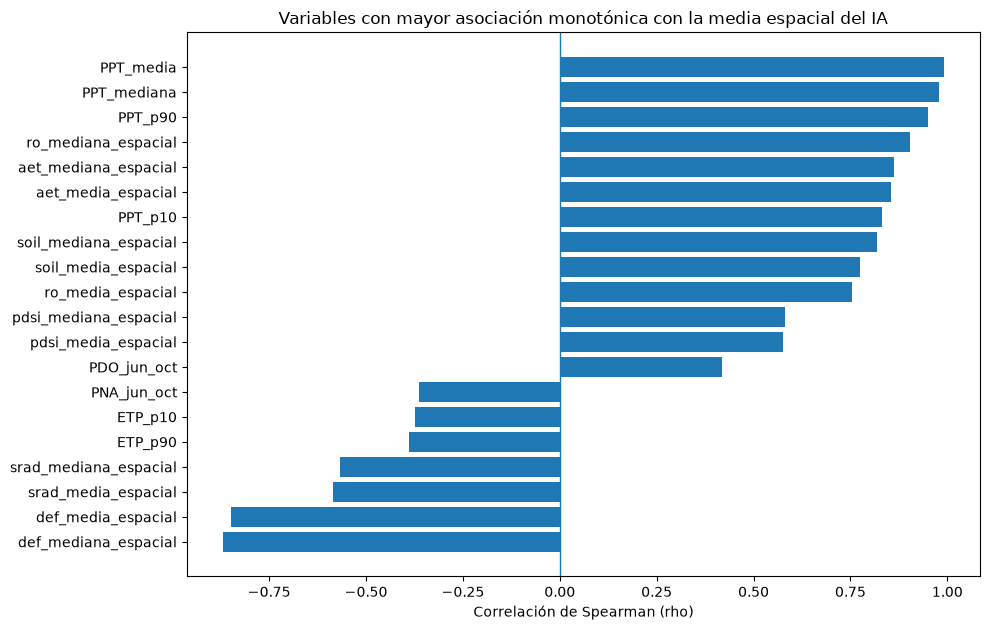

In [17]:
tabla_anual = resumen_anual.merge(indices_anuales, on="anio", how="left")
tabla_anual.to_csv(RUTA_TABLAS / "tabla_anual_IA_PPT_ETP_variables_indices.csv", index=False)

objetivo = "IA_media"
excluir = {"anio", "IA_media", "IA_mediana", "IA_p10", "IA_p90", "IA_n"}
columnas_predictoras = [c for c in tabla_anual.columns if c not in excluir and pd.api.types.is_numeric_dtype(tabla_anual[c])]
resultados_corr = []
for col in columnas_predictoras:
    pares = tabla_anual[[objetivo, col]].replace([np.inf, -np.inf], np.nan).dropna()
    if len(pares) < 4 or pares[objetivo].nunique() < 2 or pares[col].nunique() < 2:
        continue
    r_p, p_p = stats.pearsonr(pares[objetivo], pares[col])
    r_s, p_s = stats.spearmanr(pares[objetivo], pares[col])
    resultados_corr.append({
        "variable": col, "n": len(pares),
        "pearson_r": r_p, "pearson_p": p_p,
        "spearman_rho": r_s, "spearman_p": p_s,
    })

correlaciones = pd.DataFrame(resultados_corr)
if not correlaciones.empty:
    correlaciones["abs_spearman"] = correlaciones["spearman_rho"].abs()
    correlaciones = correlaciones.sort_values("abs_spearman", ascending=False)
    correlaciones.to_csv(RUTA_TABLAS / "correlaciones_variables_IA.csv", index=False)
    display(correlaciones.head(25))

    top = correlaciones.head(20).sort_values("spearman_rho")
    fig, ax = plt.subplots(figsize=(10, max(5, 0.32 * len(top))))
    ax.barh(top["variable"], top["spearman_rho"])
    ax.axvline(0, linewidth=1)
    ax.set_xlabel("Correlación de Spearman (rho)")
    ax.set_title("Variables con mayor asociación monotónica con la media espacial del IA")
    plt.tight_layout()
    fig.savefig(RUTA_FIGURAS / "correlaciones_top_IA.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("No hubo pares suficientes para calcular correlaciones.")

# Correlación entre predictores para detectar redundancia / multicolinealidad
cols_corr = [objetivo] + [c for c in columnas_predictoras if tabla_anual[c].notna().sum() >= 5]
matriz_corr = tabla_anual[cols_corr].corr(method="spearman", numeric_only=True)
matriz_corr.to_csv(RUTA_TABLAS / "matriz_correlacion_spearman_predictores.csv")

## 10. Construir panel píxel-año para entrenamiento

Opcionalmente, une IA, PPT, ETP, los 11 rasters extra y los índices anuales en filas por píxel y año. Cada índice global se replica para todos los píxeles de su año; no aporta variación espacial directa, pero sí variación temporal. Se guardará comprimido como CSV `.gz`.

**Importante para validación:** no dividas estas filas al azar entre entrenamiento y prueba. Un mismo año aporta miles de píxeles y los índices globales se repiten en todos; usa particiones por año/bloques temporales para evaluar generalización temporal. Para generalización espacial, considera además separar regiones/píxeles. El IA es una razón derivada de PPT/ETP, por lo que incluir esas dos variables contemporáneas puede permitir reconstruir casi directamente el objetivo.

In [18]:
if EXPORTAR_PANEL_PIXELES:
    indices_por_anio = indices_anuales.set_index("anio").to_dict(orient="index") if not indices_anuales.empty else {}
    bloques_panel = []

    for anio in sorted(set(resumen_anual["anio"].astype(int))):
        rutas = {
            "IA": DIR_4KM / f"IA_anual_{anio}.tif",
            "PPT": DIR_4KM / f"PPT_anual_{anio}.tif",
            "ETP": DIR_4KM / f"ETP_anual_{anio}.tif",
        }
        if not all(p.exists() for p in rutas.values()):
            continue
        ia, meta = leer_raster_nan(rutas["IA"])
        ppt, _ = leer_raster_nan(rutas["PPT"])
        etp, _ = leer_raster_nan(rutas["ETP"])
        valido = np.isfinite(ia) & np.isfinite(ppt) & np.isfinite(etp) & (etp > 0)
        filas, cols = np.where(valido)
        if len(filas) == 0:
            continue
        xs, ys = rasterio.transform.xy(meta["transform"], filas, cols, offset="center")
        bloque = pd.DataFrame({
            "anio": anio, "fila": filas, "columna": cols,
            "x": np.asarray(xs), "y": np.asarray(ys),
            "IA": ia[valido], "PPT": ppt[valido], "ETP": etp[valido],
        })

        for var in ORDEN_BANDAS_EXTRA:
            ruta_var = RUTA_EXTRA / f"tc_{var}_anual_{anio}.tif"
            if ruta_var.exists():
                arr, _ = leer_raster_nan(ruta_var)
                bloque[var] = arr[valido]
            else:
                bloque[var] = np.nan

        info_indices = indices_por_anio.get(int(anio), {})
        for nombre, valor in info_indices.items():
            if nombre != "anio":
                bloque[nombre] = valor
        bloques_panel.append(bloque)

    if bloques_panel:
        panel = pd.concat(bloques_panel, ignore_index=True)
        panel.to_csv(
            RUTA_TABLAS / "panel_pixel_anio_variables_indices.csv.gz",
            index=False, compression="gzip"
        )
        print("Panel exportado:", RUTA_TABLAS / "panel_pixel_anio_variables_indices.csv.gz")
        print("Filas:", len(panel), "| años:", panel["anio"].nunique(), "| columnas:", panel.shape[1])
        display(panel.head())
    else:
        print("No se generó panel: revisa rasters anuales y variables descargadas.")
else:
    print("Panel píxel-año desactivado en la configuración.")

Panel exportado: indice_aridez_anual\analisis_variables_extra\tablas\panel_pixel_anio_variables_indices.csv.gz
Filas: 281802 | años: 67 | columnas: 71


,anio,fila,columna,x,y,IA,PPT,ETP,aet,def,...,RONI_MAM_rezago1,RONI_AMJ_rezago1,RONI_MJJ_rezago1,RONI_JJA_rezago1,RONI_JAS_rezago1,RONI_ASO_rezago1,RONI_SON_rezago1,RONI_OND_rezago1,RONI_NDJ_rezago1,RONI_anual_media_temporadas_rezago1
0,1958,1,27,-108.512070,27.028099,0.630730,1087.0,1723.400024,1011.500000,711.700012,...,0.8,0.9,0.9,1.0,1.1,1.1,1.2,1.5,1.8,0.916667
1,1958,1,28,-108.476137,27.028099,0.603438,1053.0,1744.999878,989.700012,755.200012,...,0.8,0.9,0.9,1.0,1.1,1.1,1.2,1.5,1.8,0.916667
2,1958,1,29,-108.440204,27.028099,0.602831,1052.0,1745.099854,992.400024,752.599976,...,0.8,0.9,0.9,1.0,1.1,1.1,1.2,1.5,1.8,0.916667
3,1958,1,30,-108.404272,27.028099,0.594953,1042.0,1751.399902,985.400024,766.200012,...,0.8,0.9,0.9,1.0,1.1,1.1,1.2,1.5,1.8,0.916667
4,1958,1,31,-108.368339,27.028099,0.614323,1068.0,1738.499756,1002.399963,736.299988,...,0.8,0.9,0.9,1.0,1.1,1.1,1.2,1.5,1.8,0.916667


## 11. Archivos de salida y cómo usarlos

Carpeta `indice_aridez_anual/analisis_variables_extra/`:

- `tablas/resumen_anual_PPT_ETP_IA_variables_espaciales.csv`: medias/medianas espaciales anuales de PPT, ETP, IA y variables extra.
- `tablas/tabla_anual_IA_PPT_ETP_variables_indices.csv`: tabla anual combinada con RONI, PDO, SOI, Niño 3.4 y PNA cuando las descargas estén disponibles.
- `tablas/correlaciones_variables_IA.csv`: Pearson, Spearman y valores p exploratorios frente a IA media espacial.
- `tablas/matriz_correlacion_spearman_predictores.csv`: redundancia entre predictores.
- `tablas/panel_pixel_anio_variables_indices.csv.gz`: conjunto píxel-año opcional para entrenamiento y comparación de modelos.
- `variables_adicionales_terraclimate/tc_<variable>_anual_<año>.tif`: rasters anuales extra alineados con los mapas actuales.
- `indices_climaticos_noaa/`: CSV mensuales, estacionales y anuales descargados.

### Diseño sugerido para evaluar si mejoran las métricas

Compara con exactamente la misma separación temporal y las mismas métricas al menos: **(A)** PPT + ETP; **(B)** PPT + ETP + variables meteorológicas (`tmmn`, `tmmx`, `aet`, `soil`, `vpd`, `vap`, `srad`, `vs`, `ro`); **(C)** conjunto B + PDO/SOI/Niño 3.4/PNA/RONI; **(D)** conjunto C + `def` y `pdsi` como prueba de sensibilidad, no como evidencia de predicción independiente. Mide RMSE, MAE y R² en años de prueba que no se usaron al elegir variables. Cuando se trate de pronóstico real, usa predictores rezagados y verifica que cada variable hubiese estado disponible en la fecha del pronóstico.

### Notas para la tesis

TerraClimate aporta variables climáticas/modeladas a una malla nominal de aproximadamente 4 km. Las variables no son observaciones independientes entre sí y varias derivan del mismo sistema de balance hídrico. Documenta las bandas, factores de escala, periodos y fuentes en la metodología; no presentes una correlación como causalidad ni como una mejora de métricas hasta entrenar y validar los modelos con particiones comparables.